# 2. Calidad e integridad

Se comprueban continuidad horaria, duplicados, faltantes, rangos y observaciones extremas. Los valores anómalos se conservan en los datos originales.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


horas                   192864
horas_ausentes               0
duplicados                   0
objetivo_nulo                0
objetivo_no_positivo         0
dtype: int64

,demanda_GWh,razon_semanal
inicio,,
2002-03-16 23:00:00-05:00,2.089924,0.494457
2002-03-17 00:00:00-05:00,1.885344,0.487262
2007-04-26 10:00:00-05:00,0.413149,0.061439
2007-04-26 11:00:00-05:00,0.856097,0.125170
2007-04-26 12:00:00-05:00,2.572178,0.390730


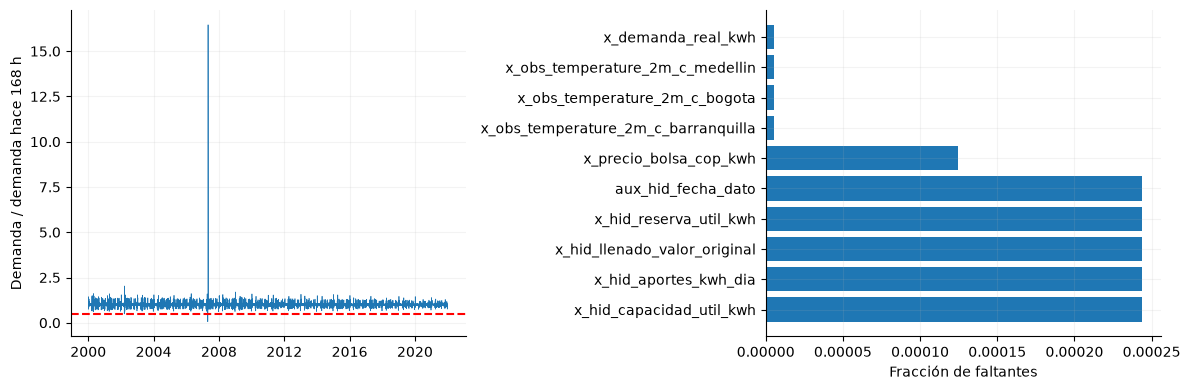

In [2]:
faltantes=len(pd.date_range(panel.index.min(),panel.index.max(),freq='h').difference(panel.index)); duplicados=panel.index.duplicated().sum(); display(pd.Series({'horas':len(panel),'horas_ausentes':faltantes,'duplicados':duplicados,'objetivo_nulo':int(y.isna().sum()),'objetivo_no_positivo':int((y<=0).sum())})); nulos=panel.isna().mean().sort_values(ascending=False)
razon=y/y.shift(168); anomalas=razon[razon<.5]; display(pd.DataFrame({'demanda_GWh':gwh.loc[anomalas.index],'razon_semanal':anomalas})); n_anomalas=len(anomalas)
fig,axes=plt.subplots(1,2,figsize=(12,4)); axes[0].plot(y.index,razon,lw=.5); axes[0].axhline(.5,color='r',ls='--'); axes[0].set_ylabel('Demanda / demanda hace 168 h'); axes[1].barh(nulos.head(10).index,nulos.head(10)); axes[1].set_xlabel('Fracción de faltantes'); fig.tight_layout(); display(fig); plt.close(fig)

Se identifican 0 horas ausentes y 0 duplicados en desarrollo. Hay 5 horas con demanda inferior a la mitad de su referencia semanal; requieren revisión de fuente y contexto antes de cualquier corrección.

## Rangos y coherencia de las mediciones

Se comprueban valores finitos y restricciones de interpretación: humedad entre 0 y 100 %, precipitación no negativa y almacenamiento no negativo. El llenado superior a uno se registra por separado para contrastarlo con reserva y capacidad; no se corrige ni se interpreta automáticamente como un porcentaje.

In [3]:
controles=[]
for col in panel.select_dtypes(include='number'):
    s=panel[col]; valida=s.dropna()
    if 'relative_humidity' in col: fuera=(valida<0)|(valida>100)
    elif 'precipitation' in col or col in ['x_hid_reserva_util_kwh','x_hid_aportes_kwh_dia']: fuera=valida<0
    elif col=='x_hid_capacidad_util_kwh': fuera=valida<=0
    else: fuera=pd.Series(False,index=valida.index)
    controles.append({'variable':col,'no_finitos_no_nulos':int((~np.isfinite(valida)).sum()),'fuera_rango':int(fuera.sum())})
controles=pd.DataFrame(controles)
incidencias=controles.loc[(controles.no_finitos_no_nulos>0)|(controles.fuera_rango>0)]
if len(incidencias): display(incidencias)
n_rango=int(controles.fuera_rango.sum()); n_inf=int(controles.no_finitos_no_nulos.sum())
hid=panel[['x_hid_llenado_valor_original','x_hid_reserva_util_kwh','x_hid_capacidad_util_kwh']].dropna()
desacuerdo=(hid.iloc[:,0]-hid.iloc[:,1]/hid.iloc[:,2]).abs()
error_ratio=float(desacuerdo.max())
fechas_sobreuno=panel.loc[panel.x_hid_llenado_valor_original>1,'aux_hid_fecha_dato'].nunique()


Se registran 0 incumplimientos de los rangos evaluados y 0 valores infinitos no nulos. El llenado supera uno en 31 fechas hidráulicas distintas; la discrepancia máxima entre el indicador y reserva/capacidad es 5e-06. Las cifras repetidas por hora reflejan la frecuencia diaria de la fuente, no mediciones hidráulicas independientes.

## Representatividad geográfica y poblacional

Las series meteorológicas representan puntos de malla próximos a ocho ciudades. La distancia al punto solicitado cuantifica una diferencia de localización, no el error de temperatura o precipitación. Los pesos poblacionales son estáticos: no describen la distribución histórica del consumo eléctrico ni la evolución demográfica anual.

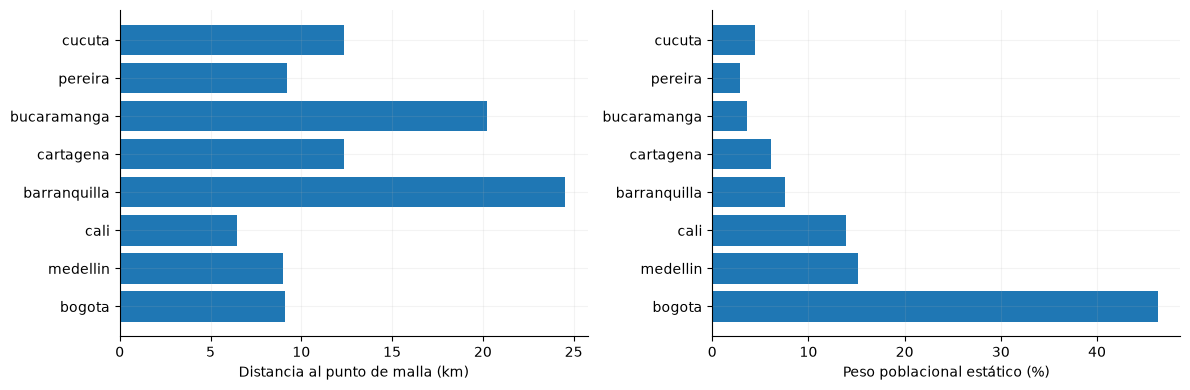

In [4]:
geo=pd.read_csv(ROOT/'data/raw/numeric/ciudades.csv')
lat1=np.radians(geo.lat_solicitada); lat2=np.radians(geo.lat_malla)
dlat=lat2-lat1; dlon=np.radians(geo.lon_malla-geo.lon_solicitada)
a=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
geo['distancia_km']=6371*2*np.arcsin(np.sqrt(a.clip(0,1)))
geo['peso']=geo.habitantes_censo_2018_ajustado/geo.habitantes_censo_2018_ajustado.sum()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].barh(geo.ciudad,geo.distancia_km); axes[0].set_xlabel('Distancia al punto de malla (km)')
axes[1].barh(geo.ciudad,100*geo.peso); axes[1].set_xlabel('Peso poblacional estático (%)')
fig.tight_layout(); display(fig); plt.close(fig)
distancia_max=float(geo.distancia_km.max()); ciudad_peso=geo.loc[geo.peso.idxmax(),'ciudad']; peso_max=float(100*geo.peso.max())


La separación máxima entre coordenada solicitada y malla es 24.54 km. bogota concentra el 46.3 % del promedio ponderado, por lo que esa representación puede atenuar condiciones de ciudades con menor peso. Validar el error meteorológico requiere estaciones emparejadas; la proximidad geográfica no basta para estimarlo.

**Decisión.** Mantener los extremos y documentar los nulos introducidos por rezagos.

**Impacto.** Evita confundir indisponibilidad inicial con huecos de la fuente.

**Riesgo.** Eliminar observaciones atípicas sin evidencia puede suprimir eventos reales.